# Video-based heart rate estimation

Exploratory remote photoplethysmography (rPPG) notebook: heart rate is estimated from the periodic colour change of a small skin region in a video, using band-pass filtering and peak counting.

# Introduction

The heartbeat slightly modulates the light reflected by skin. This notebook averages the colour channels over a small region of interest (ROI) in every frame, band-pass filters the resulting time series around plausible heart rates, and estimates the rate from the number of detected peaks. A spectral view (FFT) of the filtered signals is also shown.

The analysis is run on three recordings. A control on a background (neutral) region of recording 1 is used to check whether the estimate really depends on the skin signal.

**Reproducibility notes**

- The recordings are not distributed (see `data/README.md`). Expected file names: `data/videos/recording_1.mp4`, `recording_2.mp4`, `recording_3.mp4`.
- ROI selection is interactive (OpenCV window). The saved outputs were produced by replaying the original click coordinates: recording 1 ROI (299, 131) and neutral region (3, 340); recording 2 ROI (243, 104); recording 3 ROI (404, 339).
- The preview frames that show the ROI selection have been removed from the saved outputs because they show people.
- The saved outputs come from a re-execution (OpenCV 5.0.0, SciPy 1.18.1). They differ slightly from the outputs of the original 2024 run; see the README.

## Contents

I. Load the video and select regions

II. RGB intensity in the ROI

III. Filtered RGB signals, peak detection, heart rate

IV. Frequency analysis of the filtered RGB signals

V. YCrCb intensity in the ROI

VI. Filtered YCrCb signals, peak detection, heart rate

VII. Frequency analysis of the filtered YCrCb signals

VIII. Neutral-region control (recording 1)

IX. Recording 2

X. Recording 3

## Libraries

In [1]:
# Image and video input/output (OpenCV).
import cv2

# Plotting.
import matplotlib.pyplot as plt

# Numerical computing and array manipulation.
import numpy as np

# Digital filter design and application.
from scipy.signal import butter, filtfilt

# Peak detection.
from scipy.signal import find_peaks


# I. Load the video and select regions

- **Load the video** with OpenCV.

- **Region of interest.** The first frame is read and shown. A mouse callback records the click coordinates. A single click gives the top-left corner `(x, y)` of a fixed `n x m` pixel ROI; the release point is recorded but only the press point is used.

- **Neutral region.** The same procedure on a background area without motion, used as a comparison. Its corner is stored in `(x2, y2)`.

- **Region size.** `n` and `m` set the width and height of the analysed region, in pixels (5 x 5 here).

In [2]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_1.mp4')

# Read one frame of the video
ret, frame = cap.read()

# Display the frame
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title('Select the region of interest with the mouse')
plt.axis('off')
plt.show()

# Callback that records the mouse click coordinates
def onclick(event, x, y, flags, param):
    global roi_selected, roi_top_left, roi_bottom_right
    
    if event == cv2.EVENT_LBUTTONDOWN:
        roi_top_left = (x, y)
        roi_selected = False
    elif event == cv2.EVENT_LBUTTONUP:
        roi_bottom_right = (x, y)
        roi_selected = True

# Attach the mouse callback to the frame window
cv2.namedWindow('Frame')
cv2.setMouseCallback('Frame', onclick)

# Wait for the user to select the region of interest
roi_selected = False
roi_top_left = None
roi_bottom_right = None
while not roi_selected:
    cv2.imshow('Frame', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Close the window
cv2.destroyAllWindows()

# Extract the coordinates
x1, y1 = roi_top_left
x2, y2 = roi_bottom_right

# Print the coordinates of the selected region of interest
print("Top-left corner of the region of interest:", (x1, y1))
print("Bottom-right corner of the region of interest:", (x2, y2))

# Assign the values to x and y
x = x1
y = y1

print(f"Assigned values: x = {x}, y = {y}")

cv2.imwrite('full_frame.png', frame)
import cv2
import matplotlib.pyplot as plt

# Load the video
cap = cv2.VideoCapture('../data/videos/recording_1.mp4')

# Read one frame of the video
ret, frame = cap.read()

# Display the frame
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title('Select the neutral region with the mouse')
plt.axis('off')
plt.show()

# Callback that records the mouse click coordinates
def onclick(event, x, y, flags, param):
    global roi_selected, roi_top_left, roi_bottom_right
    
    if event == cv2.EVENT_LBUTTONDOWN:
        roi_top_left = (x, y)
        roi_selected = False
    elif event == cv2.EVENT_LBUTTONUP:
        roi_bottom_right = (x, y)
        roi_selected = True

# Attach the mouse callback to the frame window
cv2.namedWindow('Frame')
cv2.setMouseCallback('Frame', onclick)

# Wait for the user to select the region of interest
roi_selected = False
roi_top_left = None
roi_bottom_right = None
while not roi_selected:
    cv2.imshow('Frame', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Close the window
cv2.destroyAllWindows()

# Extract the coordinates
x1, y1 = roi_top_left
x2, y2 = roi_bottom_right

# Print the coordinates of the selected region of interest
print("Top-left corner of the region of interest:", (x1, y1))
print("Bottom-right corner of the region of interest:", (x2, y2))

# Assign the values to x and y
x2 = x1
y2 = y1

print(f"Assigned values: x = {x2}, y = {y2}")

cv2.imwrite('full_frame.png', frame)

# Width and height of the region (pixels):
n=5
m=5

Top-left corner of the region of interest: (299, 131)
Bottom-right corner of the region of interest: (299, 131)
Assigned values: x = 299, y = 131


Top-left corner of the region of interest: (3, 340)
Bottom-right corner of the region of interest: (3, 340)
Assigned values: x = 3, y = 340


# II. RGB intensity in the ROI

- **Frame loop.** Every frame is read in turn. The `n x m` ROI starting at `(x, y)` is extracted.

- **Channel means.** The mean of each colour channel (red, green, blue) over the ROI is computed and truncated to an integer in the range 0-255. OpenCV frames are in BGR order, so the red channel is index 2.

- **Storage and plot.** The means and the frame timestamps are stored in lists and the three raw curves are plotted against time.

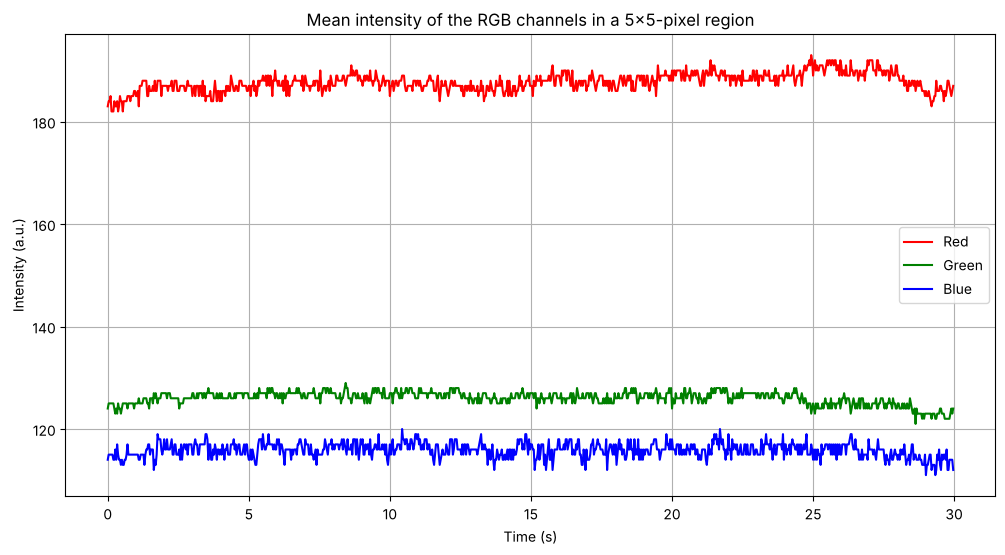

In [3]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_1.mp4')

# Clip duration in seconds (typed in manually):
clip_duration_s=30
# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x
    start_y = y

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds
    
# Release the video capture
cap.release()

# Plot intensity over time
plt.figure(figsize=(12, 6))
plt.plot(time, red_intensity, color='red', label='Red')
plt.plot(time, green_intensity, color='green', label='Green')
plt.plot(time, blue_intensity, color='blue', label='Blue')
plt.title('Mean intensity of the RGB channels in a 5x5-pixel region')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()

# III. Filtered RGB signals, peak detection, heart rate

- **Filtering.** A 4th-order Butterworth band-pass filter (`scipy.signal.butter`, applied with `filtfilt`) is applied to each colour curve. The cut-off frequencies are set in the code: **1.67-2.67 Hz (100-160 bpm) for recording 1** and 0.7-3 Hz (42-180 bpm) for recordings 2 and 3.

- **Peak detection.** `scipy.signal.find_peaks(height=0)` counts every local maximum above zero in each filtered curve. No minimum distance or prominence is imposed.

- **Heart rate.** The peak counts of the three channels are averaged and scaled by `60 / clip_duration_s` (the duration is typed in manually). The code prints `int(value) + 1`.

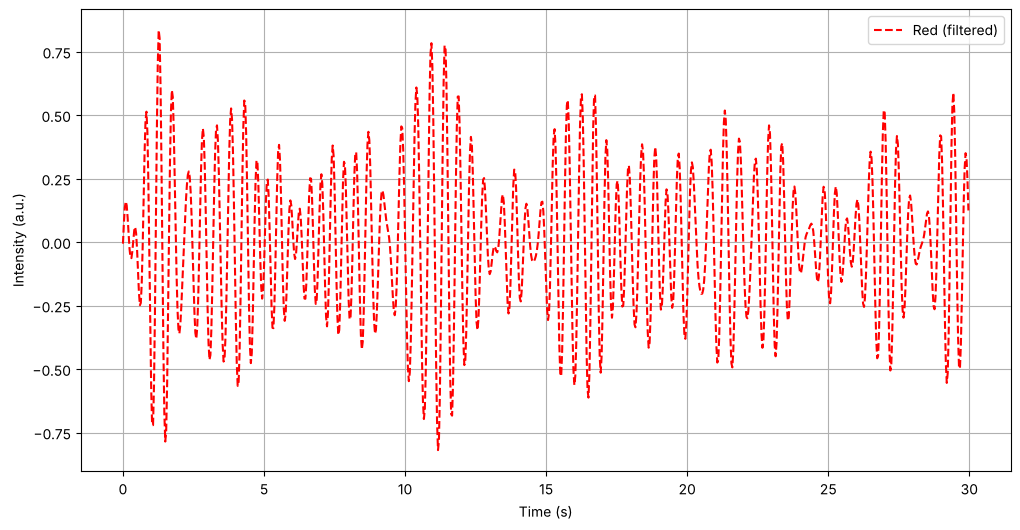

Peaks in the red channel: 65


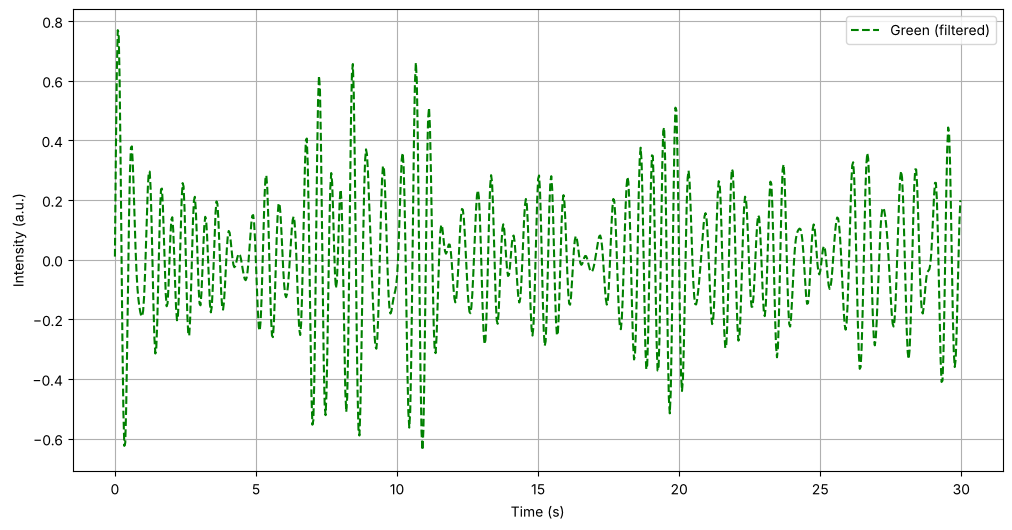

Peaks in the green channel: 64


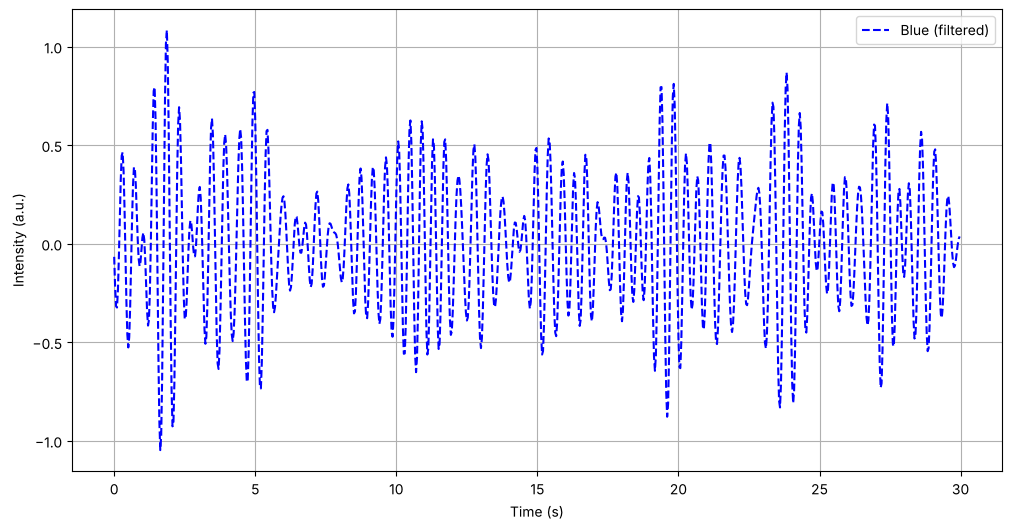

Peaks in the blue channel: 67
Mean heart rate (bpm): 131


In [4]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_1.mp4')

# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Sampling rate (frames per second)
fs = 30

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x
    start_y = y

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds

# Release the video capture
cap.release()

# Band-pass filter applied to each colour curve (cut-off frequencies set below)
lowcut = 1.67
highcut = 2.67
order = 4
b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
red_filtered = filtfilt(b, a, red_intensity)
green_filtered = filtfilt(b, a, green_intensity)
blue_filtered = filtfilt(b, a, blue_intensity)

# Number of peaks, red channel
red_peaks, _ = find_peaks(red_filtered, height=0)
num_red_peaks = len(red_peaks)

# Number of peaks, green channel
green_peaks, _ = find_peaks(green_filtered, height=0)
num_green_peaks = len(green_peaks)

# Number of peaks, blue channel
blue_peaks, _ = find_peaks(blue_filtered, height=0)
num_blue_peaks = len(blue_peaks)

# Plot intensity over time
plt.figure(figsize=(12, 6))
plt.plot(time, red_filtered, color='red', linestyle='--', label='Red (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the red channel:", num_red_peaks)

plt.figure(figsize=(12, 6))
plt.plot(time, green_filtered, color='green', linestyle='--', label='Green (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the green channel:", num_green_peaks)

plt.figure(figsize=(12, 6))
plt.plot(time, blue_filtered, color='blue', linestyle='--', label='Blue (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the blue channel:", num_blue_peaks)

coeff=60/clip_duration_s

mean_peaks_scaled=((num_green_peaks+num_red_peaks+num_blue_peaks)/3)*coeff
print("Mean heart rate (bpm):", int(mean_peaks_scaled)+1)

# IV. Frequency analysis of the filtered RGB signals

- **Fourier transform.** `np.fft.fft` of each filtered channel.

- **Frequencies.** `np.fft.fftfreq` gives the frequency axis in Hz.

- **Spectra.** The magnitude spectrum of each channel is plotted in its own subplot.

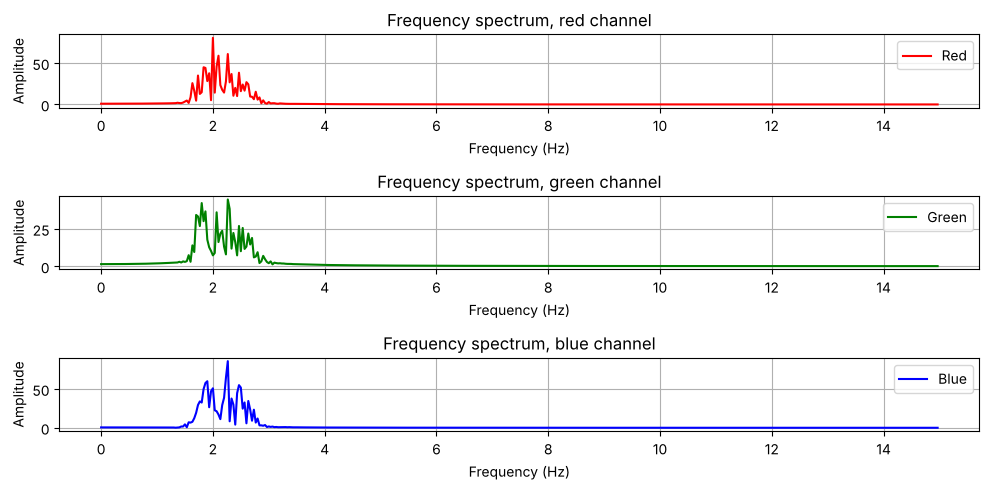

In [5]:
# Fourier transform of each filtered signal
fft_r = np.fft.fft(red_filtered)
fft_g = np.fft.fft(green_filtered)
fft_b = np.fft.fft(blue_filtered)

# Corresponding frequencies
freq = np.fft.fftfreq(len(time), d=1/fs)

# Plot the frequency spectra
plt.figure(figsize=(10, 5))

# Red channel spectrum
plt.subplot(3, 1, 1)
plt.plot(freq[:len(freq)//2], np.abs(fft_r)[:len(freq)//2], color='red', label='Red')
plt.title('Frequency spectrum, red channel')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

# Green channel spectrum
plt.subplot(3, 1, 2)
plt.plot(freq[:len(freq)//2], np.abs(fft_g)[:len(freq)//2], color='green', label='Green')
plt.title('Frequency spectrum, green channel')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

# Blue channel spectrum
plt.subplot(3, 1, 3)
plt.plot(freq[:len(freq)//2], np.abs(fft_b)[:len(freq)//2], color='blue', label='Blue')
plt.title('Frequency spectrum, blue channel')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# V. YCrCb intensity in the ROI

- **Colour space conversion.** Each frame is converted from BGR to YCrCb with `cv2.cvtColor`, separating luminance (Y) from chrominance (Cr, Cb).

- **Channel means.** The mean of Y, Cr and Cb over the same `n x m` ROI is computed for every frame.

- **Storage and plot.** The means and timestamps are stored in lists and the three raw curves are plotted against time.

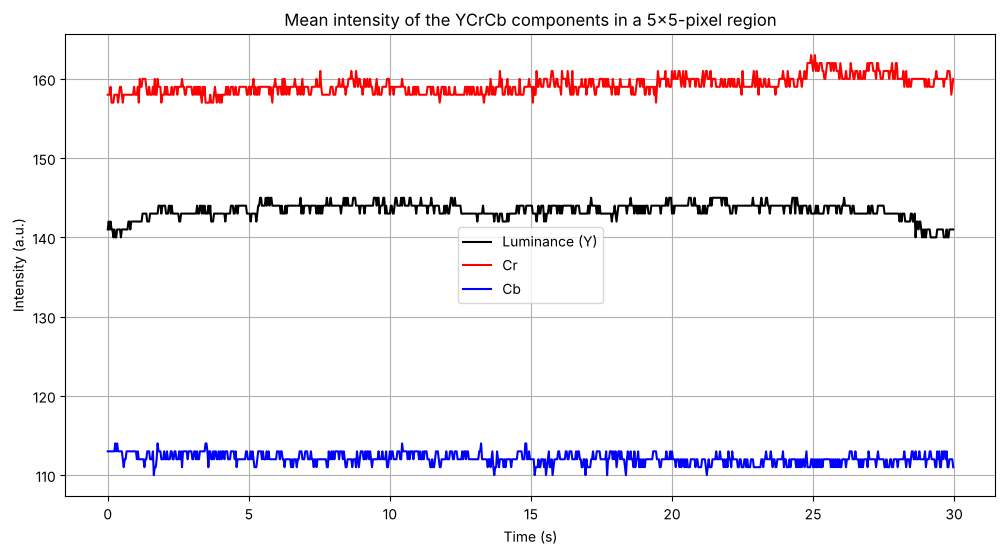

In [6]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_1.mp4')

# Lists holding the mean YCrCb values over time
y_intensity = []
cr_intensity = []
cb_intensity = []
time = []

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Convert the frame from BGR to YCrCb
    ycrcb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2YCrCb)
    
    # Starting coordinates (x, y) and ROI size (width x height)
    start_x = x
    start_y = y
    roi_width = n
    roi_height = m

    # Extract the ROI in the YCrCb colour space (n x m pixels)
    roi = ycrcb_frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean Y, Cr, Cb values over the ROI
    y_mean = np.mean(roi[:,:,0])  # Luminance (Y)
    cr_mean = np.mean(roi[:,:,1])  # Cr
    cb_mean = np.mean(roi[:,:,2])  # Cb
    
    # Append the mean values to the lists
    y_intensity.append(int(y_mean))
    cr_intensity.append(int(cr_mean))
    cb_intensity.append(int(cb_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds
    
# Release the video capture
cap.release()

# Plot intensity over time
plt.figure(figsize=(12, 6))
plt.plot(time, y_intensity, color='black', label='Luminance (Y)')
plt.plot(time, cr_intensity, color='red', label='Cr')
plt.plot(time, cb_intensity, color='blue', label='Cb')
plt.title('Mean intensity of the YCrCb components in a 5x5-pixel region')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()


# VI. Filtered YCrCb signals, peak detection, heart rate

- **Filtering.** The same band-pass filter as in section III is applied to the Y, Cr and Cb curves.

- **Peak detection.** `find_peaks(height=0)` on each filtered curve.

- **Heart rate.** Same formula as in section III: mean peak count of the three channels times `60 / clip_duration_s`.

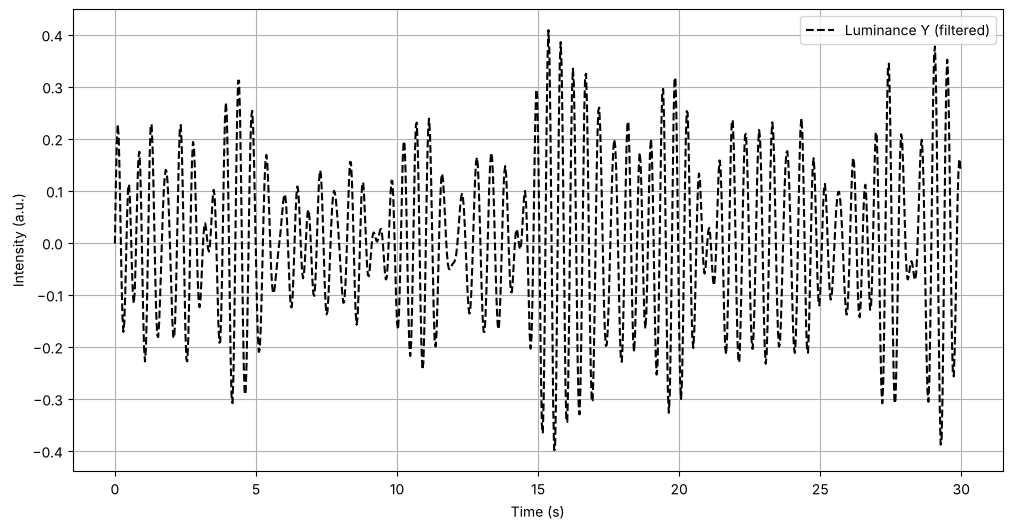

Peaks in the Y channel: 67


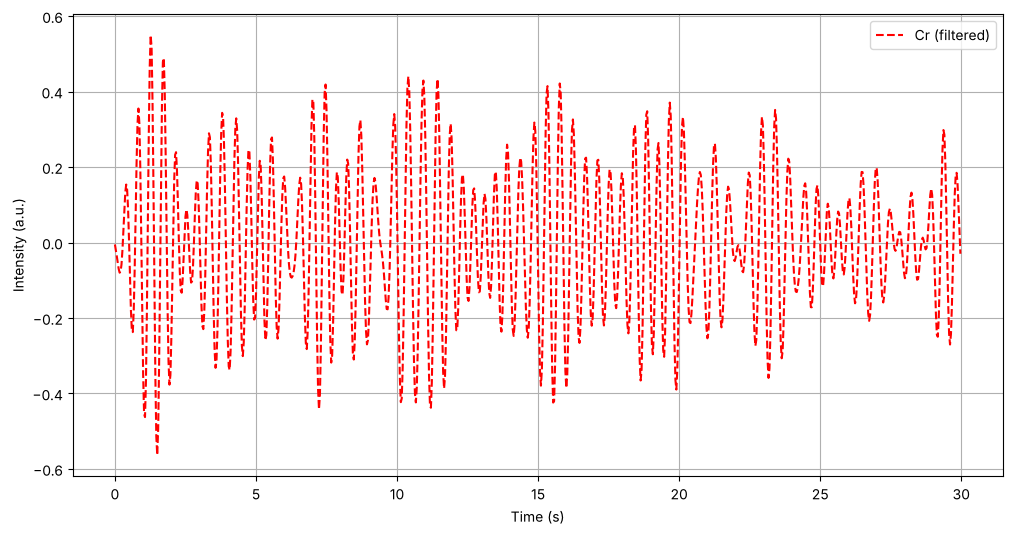

Peaks in the Cr channel: 66


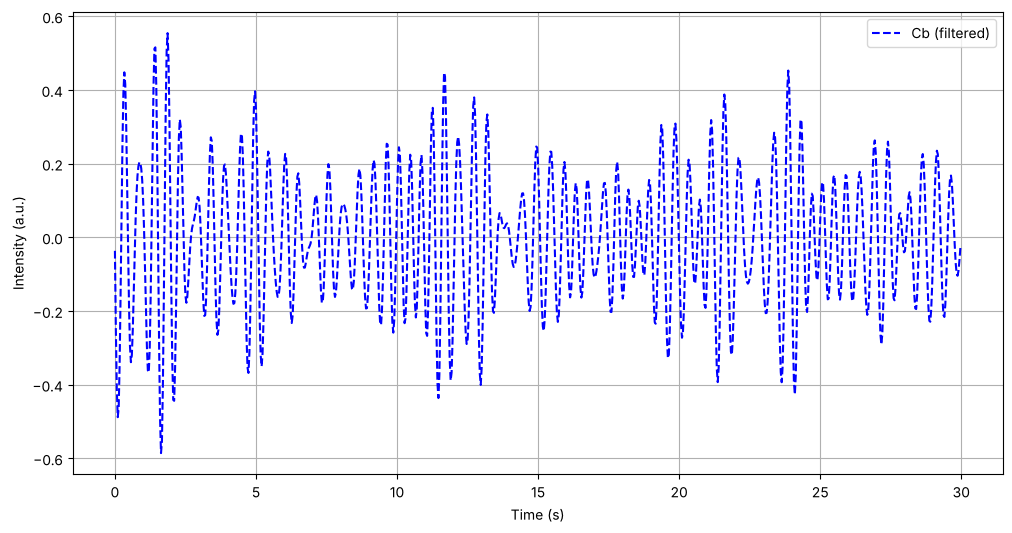

Peaks in the Cb channel: 63
Mean heart rate (bpm): 131


In [7]:
# Sampling rate (frames per second)
fs = 30

# Band-pass filter applied to each colour curve (cut-off frequencies set below)
lowcut = 1.67
highcut = 2.67
order =4 
b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
y_filtered = filtfilt(b, a, y_intensity)
cr_filtered = filtfilt(b, a, cr_intensity)
cb_filtered = filtfilt(b, a, cb_intensity)

# Number of peaks, red channel
y_peaks, _ = find_peaks(y_filtered, height=0)
num_y_peaks = len(y_peaks)

# Number of peaks, green channel
cr_peaks, _ = find_peaks(cr_filtered, height=0)
num_cr_peaks = len(cr_peaks)

# Number of peaks, blue channel
cb_peaks, _ = find_peaks(cb_filtered, height=0)
num_cb_peaks = len(cb_peaks)

# Plot intensity over time
plt.figure(figsize=(12, 6))
plt.plot(time, y_filtered, color='black', linestyle='--', label='Luminance Y (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Y channel:", num_y_peaks)

plt.figure(figsize=(12, 6))
plt.plot(time, cr_filtered, color='red', linestyle='--', label='Cr (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Cr channel:", num_cr_peaks)

plt.figure(figsize=(12, 6))
plt.plot(time, cb_filtered, color='blue', linestyle='--', label='Cb (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Cb channel:", num_cb_peaks)

coeff=60/clip_duration_s

mean_peaks_scaled=((num_y_peaks+num_cb_peaks+num_cr_peaks)/3)*coeff
print("Mean heart rate (bpm):", int(mean_peaks_scaled)+1)

# VII. Frequency analysis of the filtered YCrCb signals

- **Fourier transform.** `np.fft.fft` of each filtered channel (Y, Cr, Cb).

- **Frequencies.** `np.fft.fftfreq` gives the frequency axis in Hz.

- **Spectra.** One subplot per channel.

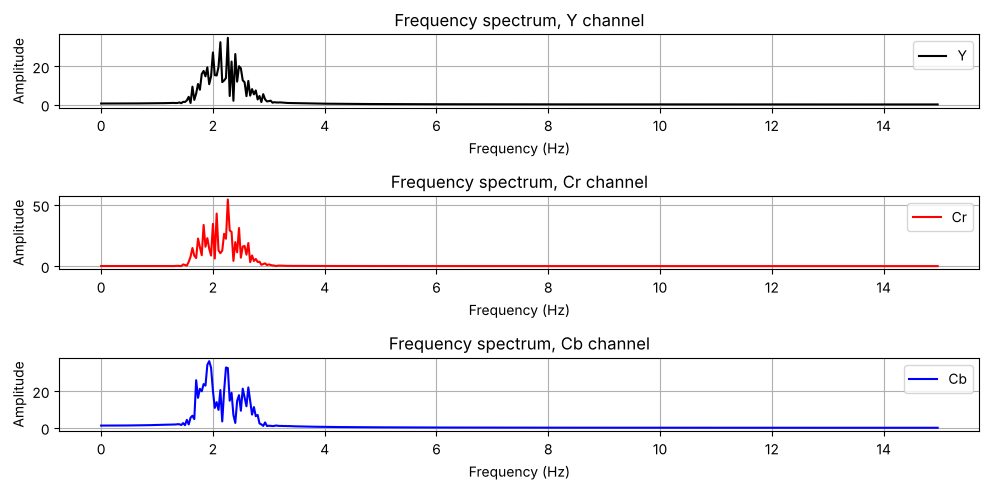

In [8]:
# Fourier transform of each filtered signal
fft_y = np.fft.fft(y_filtered)
fft_cr = np.fft.fft(cr_filtered)
fft_cb = np.fft.fft(cb_filtered)

# Corresponding frequencies
freq = np.fft.fftfreq(len(time), d=1/fs)

# Plot the frequency spectra
plt.figure(figsize=(10, 5))

# Y spectrum
plt.subplot(3, 1, 1)
plt.plot(freq[:len(freq)//2], np.abs(fft_y)[:len(freq)//2], color='black', label='Y')
plt.title('Frequency spectrum, Y channel')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

# Cr spectrum
plt.subplot(3, 1, 2)
plt.plot(freq[:len(freq)//2], np.abs(fft_cr)[:len(freq)//2], color='red', label='Cr')
plt.title('Frequency spectrum, Cr channel')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

# Cb spectrum
plt.subplot(3, 1, 3)
plt.plot(freq[:len(freq)//2], np.abs(fft_cb)[:len(freq)//2], color='blue', label='Cb')
plt.title('Frequency spectrum, Cb channel')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# VIII. Neutral-region control (recording 1)

The same RGB pipeline is run on a background region instead of the skin. If the estimate came from a cardiac signal, it should change; if it comes mostly from the pass band, it should stay the same.

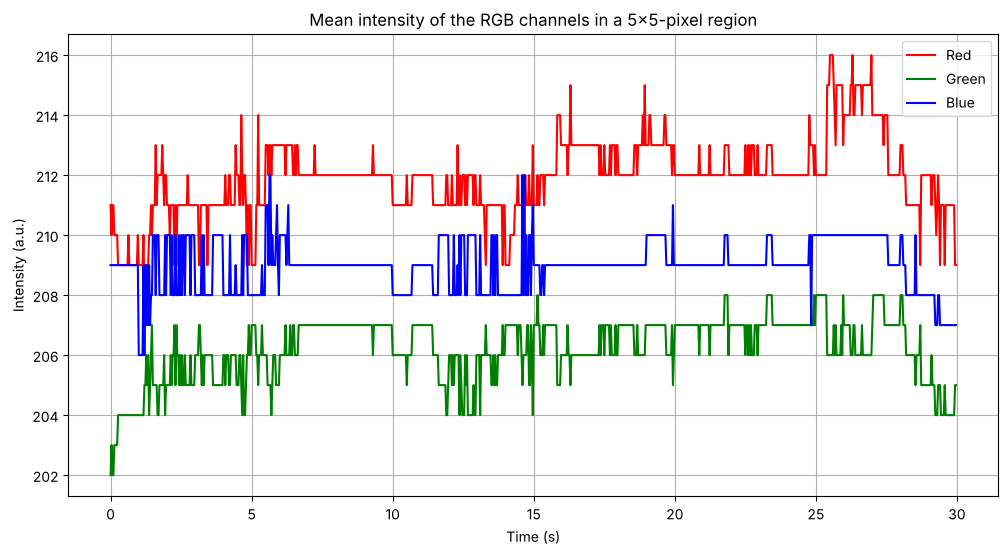

In [9]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_1.mp4')

# Clip duration in seconds (typed in manually):
clip_duration_s=30
# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x2
    start_y = y2

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds
    
# Release the video capture
cap.release()

# Plot intensity over time
plt.figure(figsize=(12, 6))
plt.plot(time, red_intensity, color='red', label='Red')
plt.plot(time, green_intensity, color='green', label='Green')
plt.plot(time, blue_intensity, color='blue', label='Blue')
plt.title('Mean intensity of the RGB channels in a 5x5-pixel region')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()

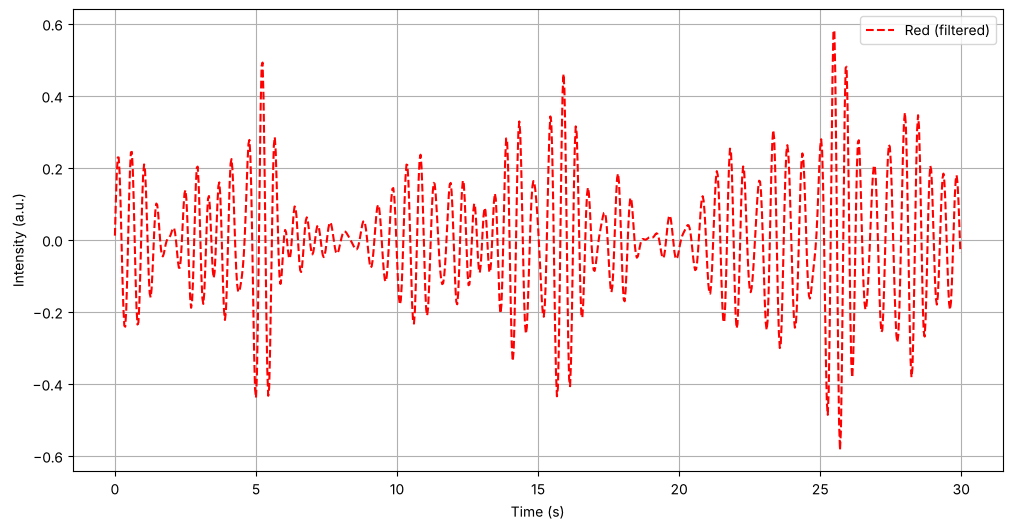

Peaks in the red channel: 64


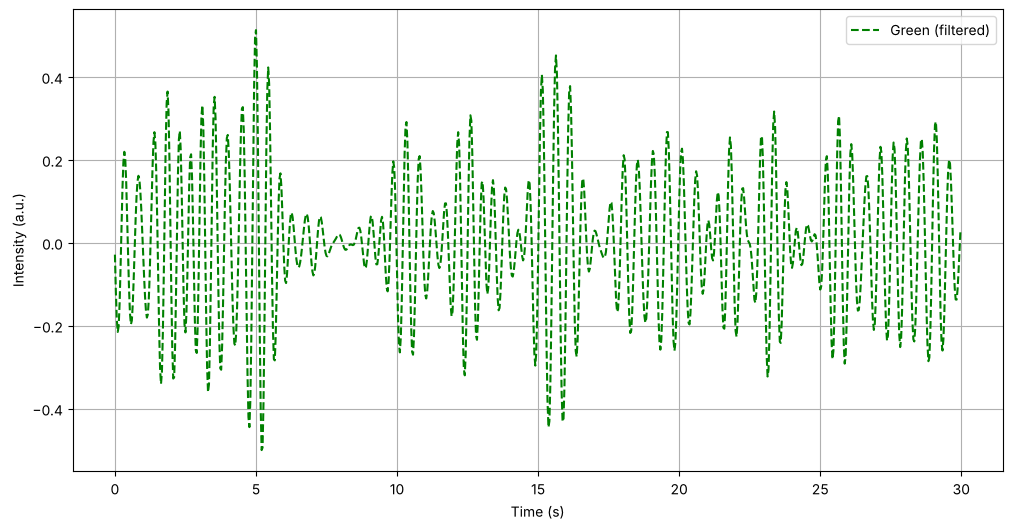

Peaks in the green channel: 64


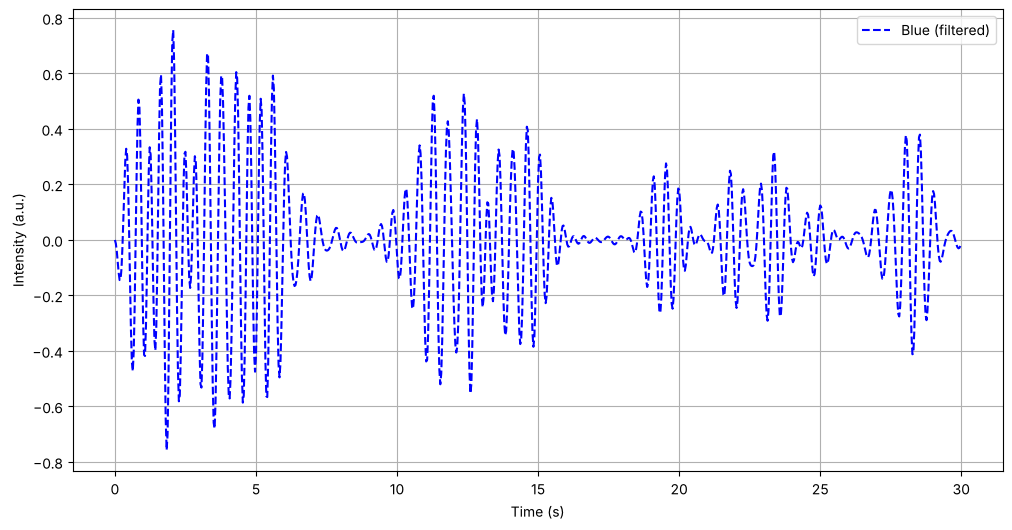

Peaks in the blue channel: 63
Mean heart rate (bpm): 128


In [10]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_1.mp4')

# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Sampling rate (frames per second)
fps = 30

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x2
    start_y = y2

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds

# Release the video capture
cap.release()

# Band-pass filter applied to each colour curve (cut-off frequencies set below)
lowcut = 1.67
highcut = 2.67
order = 4
b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
red_filtered = filtfilt(b, a, red_intensity)
green_filtered = filtfilt(b, a, green_intensity)
blue_filtered = filtfilt(b, a, blue_intensity)

# Number of peaks, red channel
red_peaks, _ = find_peaks(red_filtered, height=0)
num_red_peaks = len(red_peaks)

# Number of peaks, green channel
green_peaks, _ = find_peaks(green_filtered, height=0)
num_green_peaks = len(green_peaks)

# Number of peaks, blue channel
blue_peaks, _ = find_peaks(blue_filtered, height=0)
num_blue_peaks = len(blue_peaks)

# Plot intensity over time
plt.figure(figsize=(12, 6))
plt.plot(time, red_filtered, color='red', linestyle='--', label='Red (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the red channel:", num_red_peaks)

plt.figure(figsize=(12, 6))
plt.plot(time, green_filtered, color='green', linestyle='--', label='Green (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the green channel:", num_green_peaks)

plt.figure(figsize=(12, 6))
plt.plot(time, blue_filtered, color='blue', linestyle='--', label='Blue (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the blue channel:", num_blue_peaks)

coeff=60/clip_duration_s

mean_peaks_scaled=((num_green_peaks+num_red_peaks+num_blue_peaks)/3)*coeff
print("Mean heart rate (bpm):", int(mean_peaks_scaled)+1)

# IX. Recording 2

Same pipeline on a second recording (10 s, pass band 0.7-3 Hz), RGB then YCrCb.

Top-left corner of the region of interest: (243, 104)
Assigned values: x = 243, y = 104
Top-left corner of the region of interest: (243, 104)
Bottom-right corner of the region of interest: (243, 104)
Assigned values: x = 243, y = 104


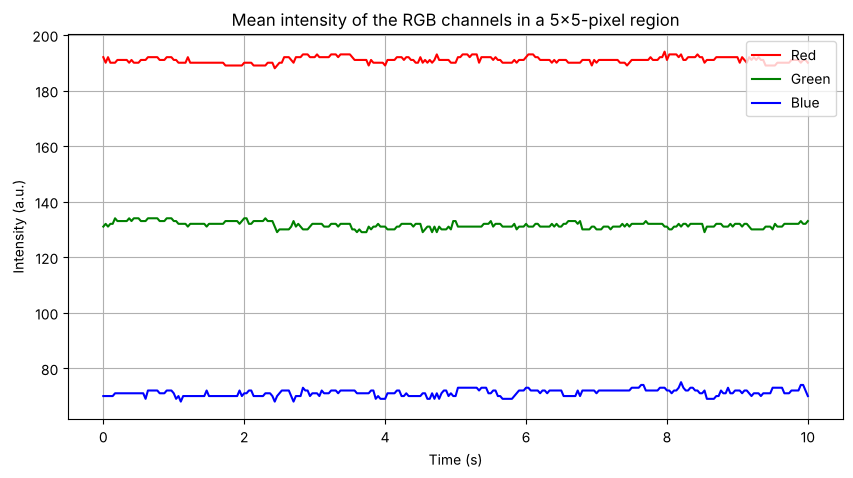

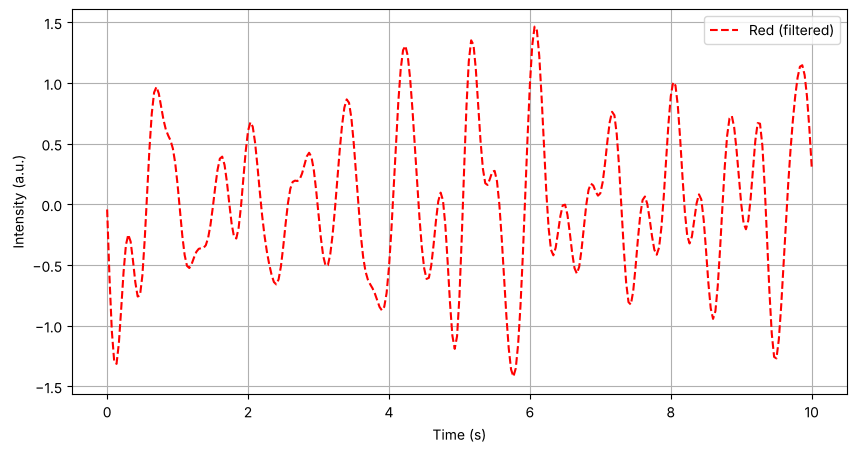

Peaks in the red channel: 19


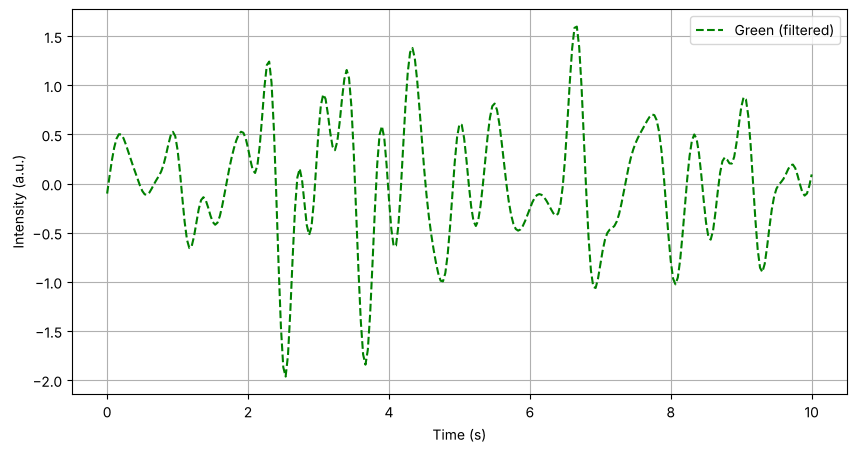

Peaks in the green channel: 17


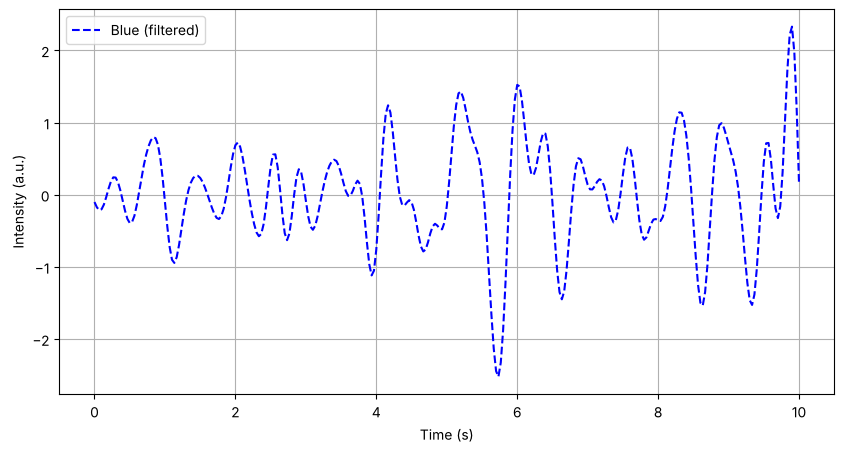

Peaks in the blue channel: 19
Mean heart rate (bpm): 111


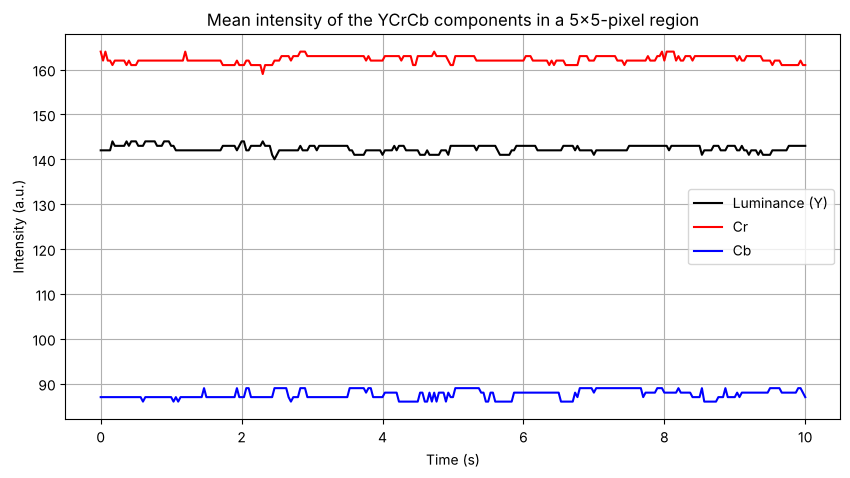

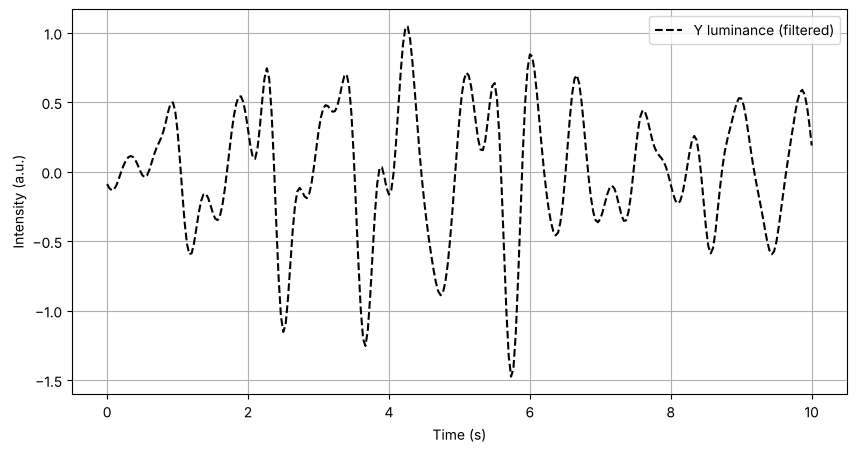

Peaks in the Y channel: 16


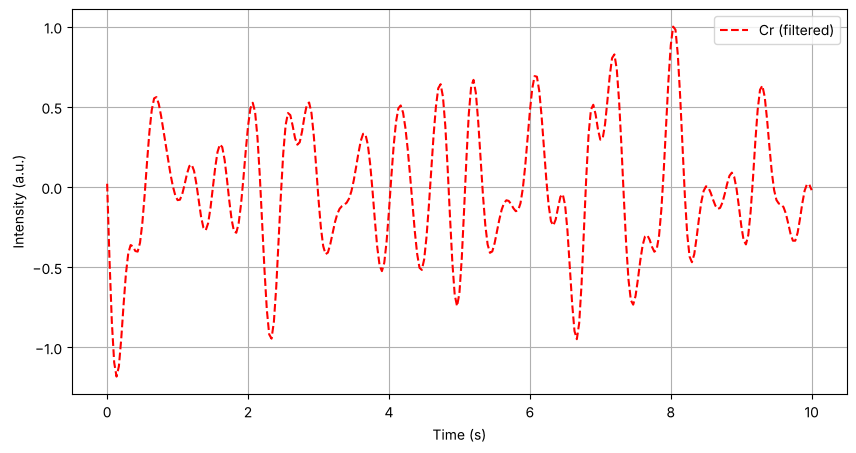

Peaks in the Cr channel: 18


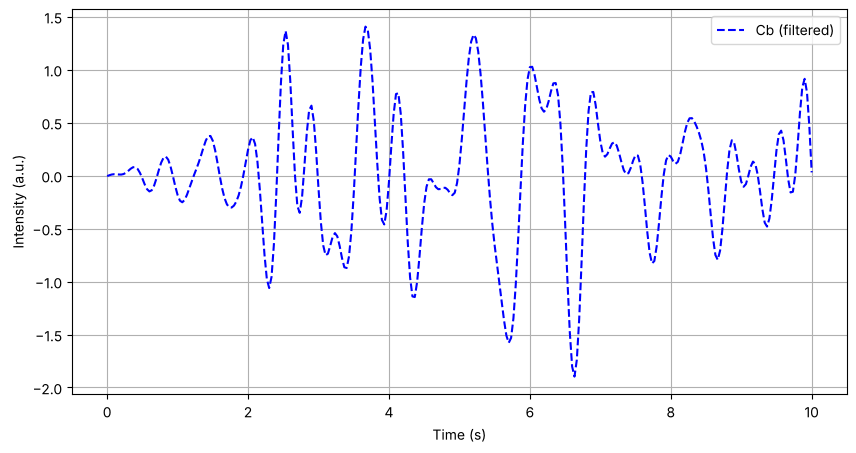

Peaks in the Cb channel: 21
Mean heart rate (bpm): 111


In [11]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_2.mp4')

# Read one frame of the video
ret, frame = cap.read()

# Clip duration (seconds)
clip_duration_s=10

# Display the frame
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title('Select the region of interest with the mouse')
plt.axis('off')
plt.show()

# Callback that records the mouse click coordinates
def onclick(event, x, y, flags, param):
    global roi_selected, roi_top_left, roi_bottom_right
    
    if event == cv2.EVENT_LBUTTONDOWN:
        roi_top_left = (x, y)
        roi_selected = False
    elif event == cv2.EVENT_LBUTTONUP:
        roi_bottom_right = (x, y)
        roi_selected = True

# Attach the mouse callback to the frame window
cv2.namedWindow('Frame')
cv2.setMouseCallback('Frame', onclick)

# Wait for the user to select the region of interest
roi_selected = False
roi_top_left = None
roi_bottom_right = None
while not roi_selected:
    cv2.imshow('Frame', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Close the window
cv2.destroyAllWindows()

# Extract the coordinates
x1, y1 = roi_top_left

# Print the coordinates of the selected region of interest
print("Top-left corner of the region of interest:", (x1, y1))

# Assign the values to x and y
x = x1
y = y1

print(f"Assigned values: x = {x}, y = {y}")

# Extract the coordinates
x1, y1 = roi_top_left
x2, y2 = roi_bottom_right

# Print the coordinates of the selected region of interest
print("Top-left corner of the region of interest:", (x1, y1))
print("Bottom-right corner of the region of interest:", (x2, y2))

# Assign the values to x and y
x2 = x1
y2 = y1

print(f"Assigned values: x = {x}, y = {y}")

cv2.imwrite('full_frame.png', frame)

# Width and height of the region (pixels):
n=5
m=5

# Load the video
cap = cv2.VideoCapture('../data/videos/recording_2.mp4')

# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x
    start_y = y

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds
    
# Release the video capture
cap.release()

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, red_intensity, color='red', label='Red')
plt.plot(time, green_intensity, color='green', label='Green')
plt.plot(time, blue_intensity, color='blue', label='Blue')
plt.title('Mean intensity of the RGB channels in a 5x5-pixel region')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()

# Load the video
cap = cv2.VideoCapture('../data/videos/recording_2.mp4')

# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Sampling rate (frames per second)
fps = 30

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x
    start_y = y

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds

# Release the video capture
cap.release()

# Sampling rate (frames per second)
fs = 30

# Band-pass filter applied to each colour curve (cut-off frequencies set below)
lowcut = 0.7
highcut = 3
order = 4
b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
red_filtered = filtfilt(b, a, red_intensity)
green_filtered = filtfilt(b, a, green_intensity)
blue_filtered = filtfilt(b, a, blue_intensity)

# Number of peaks, red channel
red_peaks, _ = find_peaks(red_filtered, height=0)
num_red_peaks = len(red_peaks)

# Number of peaks, green channel
green_peaks, _ = find_peaks(green_filtered, height=0)
num_green_peaks = len(green_peaks)

# Number of peaks, blue channel
blue_peaks, _ = find_peaks(blue_filtered, height=0)
num_blue_peaks = len(blue_peaks)

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, red_filtered, color='red', linestyle='--', label='Red (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the red channel:", num_red_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, green_filtered, color='green', linestyle='--', label='Green (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the green channel:", num_green_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, blue_filtered, color='blue', linestyle='--', label='Blue (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the blue channel:", num_blue_peaks)

coeff=60/clip_duration_s

mean_peaks_scaled=((num_green_peaks+num_red_peaks+num_blue_peaks)/3)*coeff
print("Mean heart rate (bpm):", int(mean_peaks_scaled)+1)

# Load the video
cap = cv2.VideoCapture('../data/videos/recording_2.mp4')

# Lists holding the mean YCrCb values over time
y_intensity = []
cr_intensity = []
cb_intensity = []
time = []

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Convert the frame from BGR to YCrCb
    ycrcb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2YCrCb)
    
    # Starting coordinates (x, y) and ROI size (width x height)
    start_x = x
    start_y = y
    roi_width = n
    roi_height = m

    # Extract the ROI in the YCrCb colour space (n x m pixels)
    roi = ycrcb_frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean Y, Cr, Cb values over the ROI
    y_mean = np.mean(roi[:,:,0])  # Luminance (Y)
    cr_mean = np.mean(roi[:,:,1])  # Cr
    cb_mean = np.mean(roi[:,:,2])  # Cb
    
    # Append the mean values to the lists
    y_intensity.append(int(y_mean))
    cr_intensity.append(int(cr_mean))
    cb_intensity.append(int(cb_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds
    
# Release the video capture
cap.release()

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, y_intensity, color='black', label='Luminance (Y)')
plt.plot(time, cr_intensity, color='red', label='Cr')
plt.plot(time, cb_intensity, color='blue', label='Cb')
plt.title('Mean intensity of the YCrCb components in a 5x5-pixel region')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()

# Sampling rate (frames per second)
fs = 30

# Band-pass filter applied to each colour curve (cut-off frequencies set below)
lowcut = 0.7
highcut = 3
order =4 
b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
y_filtered = filtfilt(b, a, y_intensity)
cr_filtered = filtfilt(b, a, cr_intensity)
cb_filtered = filtfilt(b, a, cb_intensity)

# Number of peaks, red channel
y_peaks, _ = find_peaks(y_filtered, height=0)
num_y_peaks = len(y_peaks)

# Number of peaks, green channel
cr_peaks, _ = find_peaks(cr_filtered, height=0)
num_cr_peaks = len(cr_peaks)

# Number of peaks, blue channel
cb_peaks, _ = find_peaks(cb_filtered, height=0)
num_cb_peaks = len(cb_peaks)

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, y_filtered, color='black', linestyle='--', label='Y luminance (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Y channel:", num_y_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, cr_filtered, color='red', linestyle='--', label='Cr (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Cr channel:", num_cr_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, cb_filtered, color='blue', linestyle='--', label='Cb (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Cb channel:", num_cb_peaks)

coeff=60/clip_duration_s

mean_peaks_scaled=((num_y_peaks+num_cr_peaks+num_cb_peaks)/3)*coeff
print("Mean heart rate (bpm):", int(mean_peaks_scaled)+1)

# X. Recording 3

Same pipeline on a third recording (30 s, pass band 0.7-3 Hz), RGB then YCrCb.

Top-left corner of the region of interest: (404, 339)
Assigned values: x = 404, y = 339
Top-left corner of the region of interest: (404, 339)
Bottom-right corner of the region of interest: (404, 339)
Assigned values: x = 404, y = 339


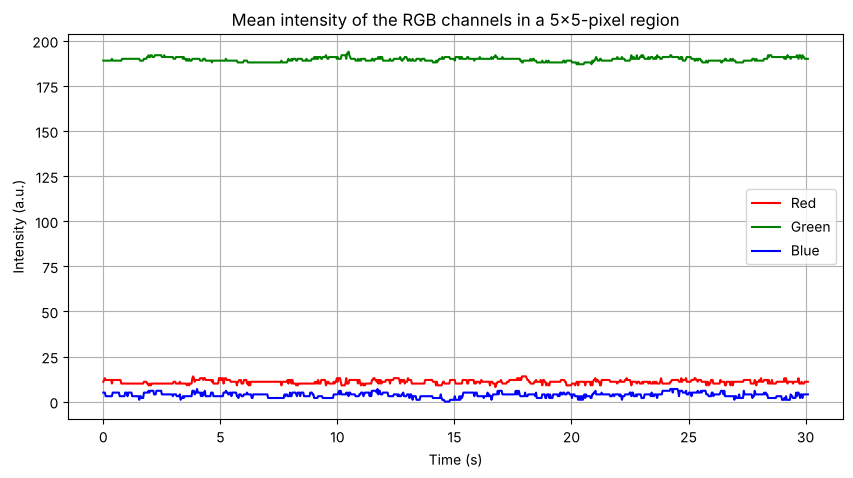

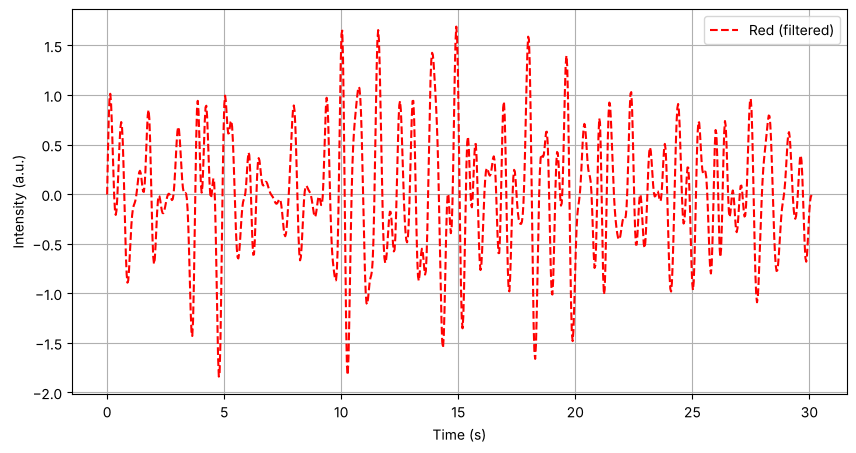

Peaks in the red channel: 56


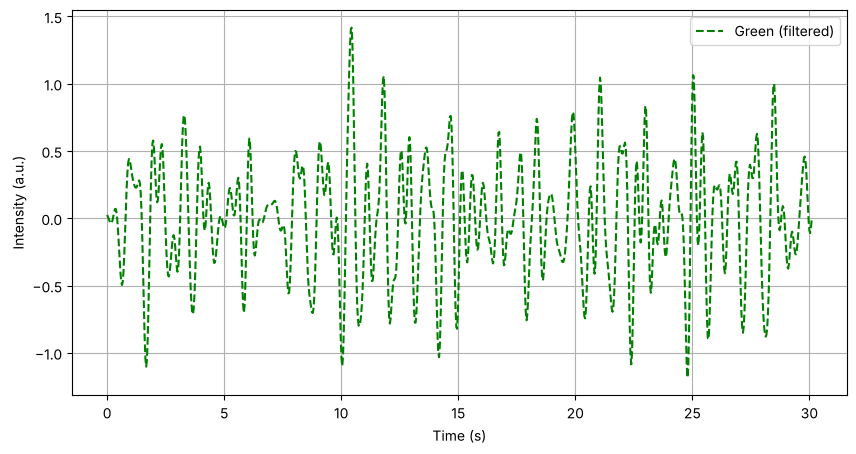

Peaks in the green channel: 54


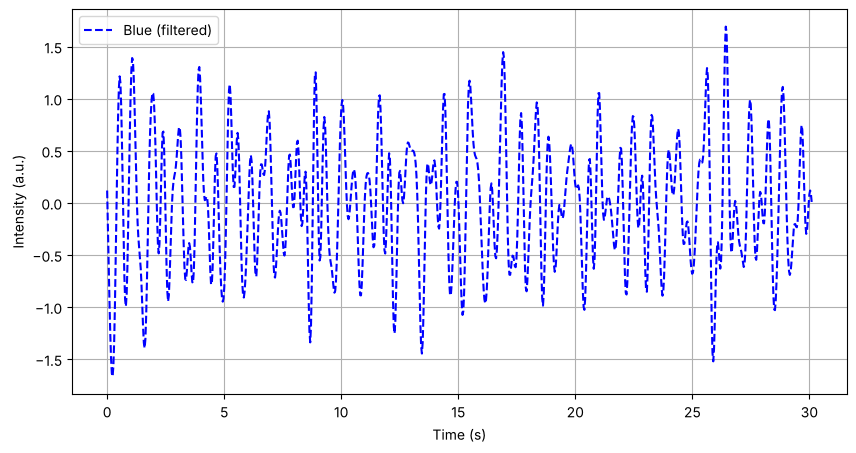

Peaks in the blue channel: 57
Mean heart rate (bpm): 112


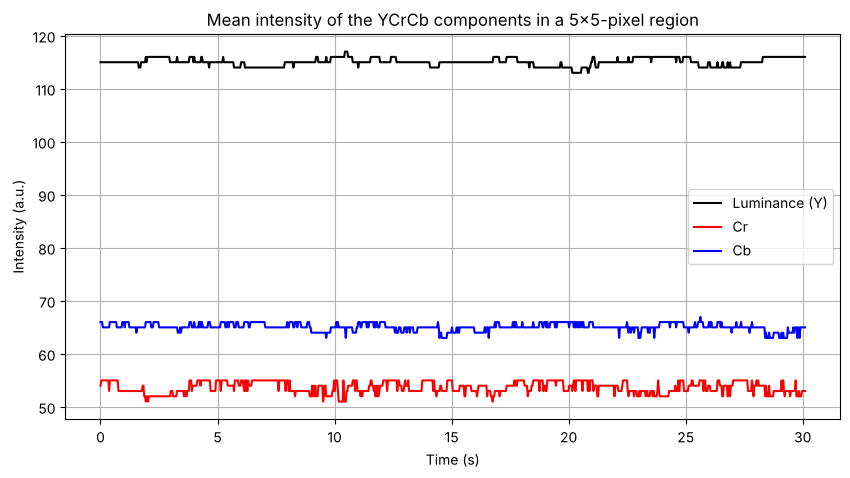

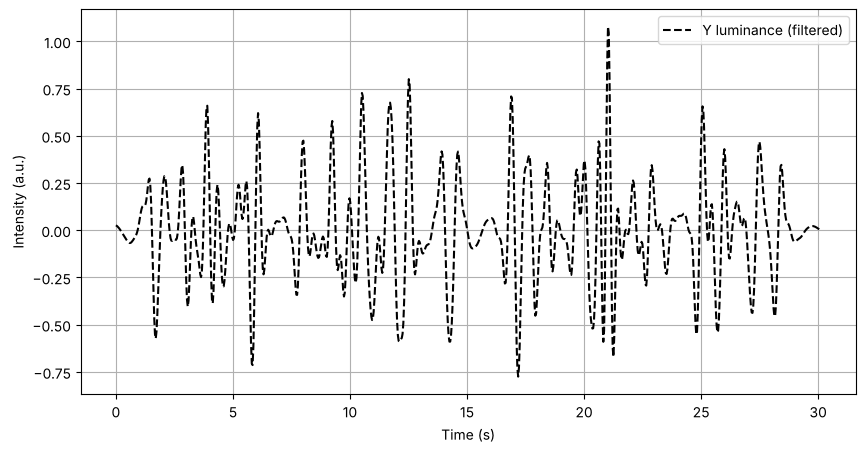

Peaks in the Y channel: 47


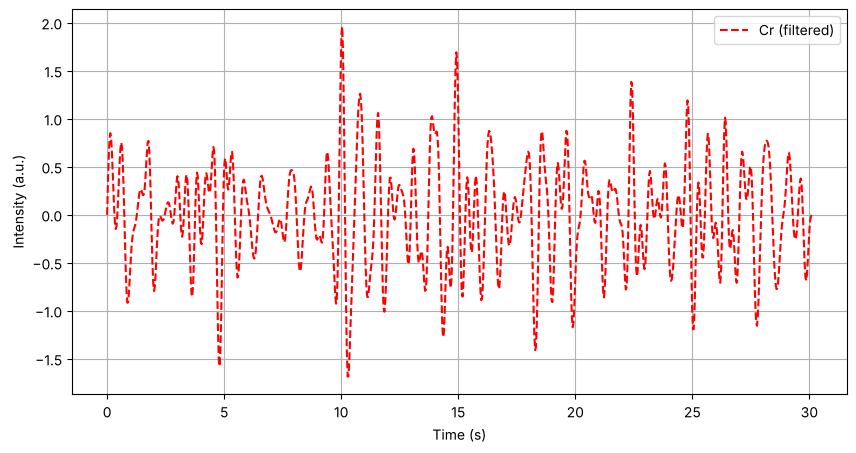

Peaks in the Cr channel: 54


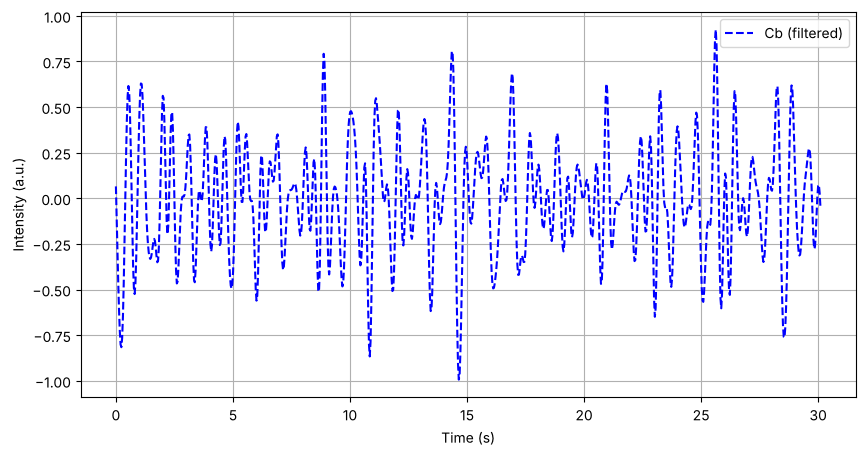

Peaks in the Cb channel: 61
Mean heart rate (bpm): 109


In [12]:
# Load the video
cap = cv2.VideoCapture('../data/videos/recording_3.mp4')

# Read one frame of the video
ret, frame = cap.read()

# Clip duration (seconds)
clip_duration_s=30

# Display the frame
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title('Select the region of interest with the mouse')
plt.axis('off')
plt.show()

# Callback that records the mouse click coordinates
def onclick(event, x, y, flags, param):
    global roi_selected, roi_top_left, roi_bottom_right
    
    if event == cv2.EVENT_LBUTTONDOWN:
        roi_top_left = (x, y)
        roi_selected = False
    elif event == cv2.EVENT_LBUTTONUP:
        roi_bottom_right = (x, y)
        roi_selected = True

# Attach the mouse callback to the frame window
cv2.namedWindow('Frame')
cv2.setMouseCallback('Frame', onclick)

# Wait for the user to select the region of interest
roi_selected = False
roi_top_left = None
roi_bottom_right = None
while not roi_selected:
    cv2.imshow('Frame', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Close the window
cv2.destroyAllWindows()

# Extract the coordinates
x1, y1 = roi_top_left

# Print the coordinates of the selected region of interest
print("Top-left corner of the region of interest:", (x1, y1))

# Assign the values to x and y
x = x1
y = y1

print(f"Assigned values: x = {x}, y = {y}")

# Extract the coordinates
x1, y1 = roi_top_left
x2, y2 = roi_bottom_right

# Print the coordinates of the selected region of interest
print("Top-left corner of the region of interest:", (x1, y1))
print("Bottom-right corner of the region of interest:", (x2, y2))

# Assign the values to x and y
x2 = x1
y2 = y1

print(f"Assigned values: x = {x}, y = {y}")

cv2.imwrite('full_frame.png', frame)

# Width and height of the region (pixels):
n=5
m=5

# Load the video
cap = cv2.VideoCapture('../data/videos/recording_3.mp4')

# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x
    start_y = y

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds
    
# Release the video capture
cap.release()

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, red_intensity, color='red', label='Red')
plt.plot(time, green_intensity, color='green', label='Green')
plt.plot(time, blue_intensity, color='blue', label='Blue')
plt.title('Mean intensity of the RGB channels in a 5x5-pixel region')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()

# Load the video
cap = cv2.VideoCapture('../data/videos/recording_3.mp4')

# Lists holding the mean RGB values over time
red_intensity = []
green_intensity = []
blue_intensity = []
time = []

# Sampling rate (frames per second)
fps = 30

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Starting coordinates (x, y)
    start_x = x
    start_y = y

    # Size of the region of interest (width x height)
    roi_width = n
    roi_height = m

    # Extract the ROI (n x m pixels)
    roi = frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean R, G, B values over the ROI (range 0-255)
    red_mean = np.mean(roi[:,:,2])  # Red
    green_mean = np.mean(roi[:,:,1])  # Green
    blue_mean = np.mean(roi[:,:,0])  # Blue
    
    # Append the mean values to the lists
    red_intensity.append(int(red_mean))
    green_intensity.append(int(green_mean))
    blue_intensity.append(int(blue_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds

# Release the video capture
cap.release()

# Sampling rate (frames per second)
fs = 30

# Band-pass filter applied to each colour curve (cut-off frequencies set below)
lowcut = 0.7
highcut = 3
order = 4
b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
red_filtered = filtfilt(b, a, red_intensity)
green_filtered = filtfilt(b, a, green_intensity)
blue_filtered = filtfilt(b, a, blue_intensity)

# Number of peaks, red channel
red_peaks, _ = find_peaks(red_filtered, height=0)
num_red_peaks = len(red_peaks)

# Number of peaks, green channel
green_peaks, _ = find_peaks(green_filtered, height=0)
num_green_peaks = len(green_peaks)

# Number of peaks, blue channel
blue_peaks, _ = find_peaks(blue_filtered, height=0)
num_blue_peaks = len(blue_peaks)

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, red_filtered, color='red', linestyle='--', label='Red (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the red channel:", num_red_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, green_filtered, color='green', linestyle='--', label='Green (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the green channel:", num_green_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, blue_filtered, color='blue', linestyle='--', label='Blue (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the blue channel:", num_blue_peaks)

coeff=60/clip_duration_s

mean_peaks_scaled=((num_green_peaks+num_red_peaks+num_blue_peaks)/3)*coeff
print("Mean heart rate (bpm):", int(mean_peaks_scaled)+1)

# Load the video
cap = cv2.VideoCapture('../data/videos/recording_3.mp4')

# Lists holding the mean YCrCb values over time
y_intensity = []
cr_intensity = []
cb_intensity = []
time = []

# Loop over every frame of the video
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Convert the frame from BGR to YCrCb
    ycrcb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2YCrCb)
    
    # Starting coordinates (x, y) and ROI size (width x height)
    start_x = x
    start_y = y
    roi_width = n
    roi_height = m

    # Extract the ROI in the YCrCb colour space (n x m pixels)
    roi = ycrcb_frame[start_y:start_y + roi_height, start_x:start_x + roi_width]
    
    # Mean Y, Cr, Cb values over the ROI
    y_mean = np.mean(roi[:,:,0])  # Luminance (Y)
    cr_mean = np.mean(roi[:,:,1])  # Cr
    cb_mean = np.mean(roi[:,:,2])  # Cb
    
    # Append the mean values to the lists
    y_intensity.append(int(y_mean))
    cr_intensity.append(int(cr_mean))
    cb_intensity.append(int(cb_mean))
    time.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)  # Convert milliseconds to seconds
    
# Release the video capture
cap.release()

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, y_intensity, color='black', label='Luminance (Y)')
plt.plot(time, cr_intensity, color='red', label='Cr')
plt.plot(time, cb_intensity, color='blue', label='Cb')
plt.title('Mean intensity of the YCrCb components in a 5x5-pixel region')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()

# Sampling rate (frames per second)
fs = 30

# Band-pass filter applied to each colour curve (cut-off frequencies set below)
lowcut = 0.7
highcut = 3
order =4 
b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
y_filtered = filtfilt(b, a, y_intensity)
cr_filtered = filtfilt(b, a, cr_intensity)
cb_filtered = filtfilt(b, a, cb_intensity)

# Number of peaks, red channel
y_peaks, _ = find_peaks(y_filtered, height=0)
num_y_peaks = len(y_peaks)

# Number of peaks, green channel
cr_peaks, _ = find_peaks(cr_filtered, height=0)
num_cr_peaks = len(cr_peaks)

# Number of peaks, blue channel
cb_peaks, _ = find_peaks(cb_filtered, height=0)
num_cb_peaks = len(cb_peaks)

# Plot intensity over time
plt.figure(figsize=(10, 5))
plt.plot(time, y_filtered, color='black', linestyle='--', label='Y luminance (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Y channel:", num_y_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, cr_filtered, color='red', linestyle='--', label='Cr (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Cr channel:", num_cr_peaks)

plt.figure(figsize=(10, 5))
plt.plot(time, cb_filtered, color='blue', linestyle='--', label='Cb (filtered)')
plt.xlabel('Time (s)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True)
plt.show()
print("Peaks in the Cb channel:", num_cb_peaks)

coeff=60/clip_duration_s

mean_peaks_scaled=((num_y_peaks+num_cr_peaks+num_cb_peaks)/3)*coeff
print("Mean heart rate (bpm):", int(mean_peaks_scaled)+1)